### 1. Loading the Fashion-MNIST Dataset


In [4]:
# Import required libraries
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist

# Load Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

#### 1.1 Check the Dataset Shape

The shapes of the training and test datasets are checked to confirm the number of images and their dimensions.

In [5]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


x_train: (60000, 28, 28) → 60,000 training images, each 28×28 pixels
y_train: (60000,)       → 60,000 corresponding labels

x_test:  (10000, 28, 28) → 10,000 test images
y_test:  (10000,)         → 10,000 corresponding labels

#### 1.2 Visualize Sample Images

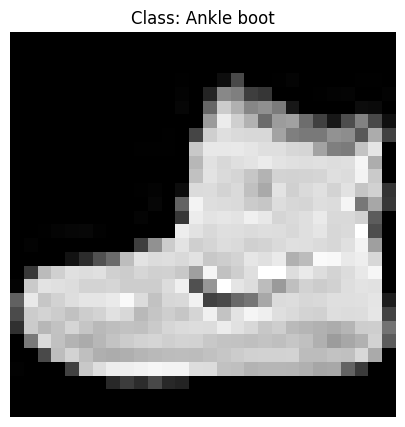

In [7]:
# Fashion-MNIST class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Display sample training images
plt.figure(figsize=(10, 5))

# Display one sample training image
plt.imshow(x_train[0], cmap='gray')
plt.title(f"Class: {class_names[y_train[0]]}")
plt.axis('off')
plt.show()

The sample image shows an ankle boot from the Fashion-MNIST training dataset. Each image is a 28 × 28 grayscale image and is associated with one of the 10 clothing classes.

#### 1.3 Normalize the Images

In [8]:
# Normalize pixel values from 0-255 to 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

The original pixel values range from 0 to 255. I divided them by 255 to scale the values between 0 and 1. This normalization makes the input values more consistent for training the neural networks.

### 2. MultiLayer Perceptron (MLP)

#### 2.1 Build the MLP Model

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Build the MLP model
MLP_Model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

MLP_Model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

The MLP first flattens each 28 × 28 image into 784 input values. These inputs are passed through two hidden Dense layers with 128 and 64 neurons using ReLU activation. The output layer contains 10 neurons with Softmax activation, representing the 10 Fashion-MNIST classes.

The model has 109,386 trainable parameters in total.

#### 2.2 Compile the MLP Model

In [10]:
MLP_Model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

The model was compiled using the Adam optimizer for updating the model weights during training. Sparse categorical cross-entropy was used because this is a multi-class classification problem with integer class labels. Accuracy was used to measure the percentage of correctly classified images.

#### 2.3 Train the Model

In [11]:
import time

# Record the starting time
start_time = time.time()

# Train the MLP model
MLP_history = MLP_Model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    verbose=1
)

# Calculate training time
MLP_training_time = time.time() - start_time

print(f"MLP Training Time: {MLP_training_time:.2f} seconds")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8242 - loss: 0.4938
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8645 - loss: 0.3694
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8783 - loss: 0.3320
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8842 - loss: 0.3112
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8920 - loss: 0.2907
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8958 - loss: 0.2775
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9012 - loss: 0.2634
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9043 - loss: 0.2544
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9087 - loss: 0.2423
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9097 - loss: 0.2375
MLP Training Time: 39.69 seconds


The MLP was trained for 10 epochs with a batch size of 32. During training, the accuracy increased from 82.42% in the first epoch to 90.97% in the final epoch, while the loss decreased from 0.4938 to 0.2375. This shows that the model gradually learned to classify the training images more accurately. The total training time was 39.69 seconds.

#### 2.4 Evaluate the MLP Model

In [12]:
# Evaluate the MLP on the test dataset
MLP_test_loss, MLP_test_accuracy = MLP_Model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"MLP Test Accuracy: {MLP_test_accuracy * 100:.2f}%")
print(f"MLP Test Loss: {MLP_test_loss:.4f}")

MLP Test Accuracy: 88.30%
MLP Test Loss: 0.3393


The MLP achieved a test accuracy of 88.30% with a test loss of 0.3393. The test accuracy is slightly lower than the final training accuracy of 90.97%, showing that the model performs somewhat better on the training data than on unseen test images.

#### 2.5 Store the MLP Results

In [13]:
# Store MLP results for later comparison
MLP_results = {
    "Training Accuracy": MLP_history.history['accuracy'][-1],
    "Training Loss": MLP_history.history['loss'][-1],
    "Test Accuracy": MLP_test_accuracy,
    "Test Loss": MLP_test_loss,
    "Parameters": MLP_Model.count_params(),
    "Training Time": MLP_training_time
}

MLP_results

{'Training Accuracy': 0.9097166657447815,
 'Training Loss': 0.23752106726169586,
 'Test Accuracy': 0.8830000162124634,
 'Test Loss': 0.3393022119998932,
 'Parameters': 109386,
 'Training Time': 39.69107365608215}

### 3. Convolutional Neural Network (CNN)

#### 3.1 Build the CNN Model

In [14]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Build the CNN model
CNN_Model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

CNN_Model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

The CNN uses two convolutional layers with 32 and 64 filters to extract features from the images. Each convolutional layer is followed by a max-pooling layer to reduce the size of the feature maps. The extracted features are then flattened and passed through a Dense layer with 64 neurons, followed by a 10-neuron output layer for classification.

The CNN contains 121,930 trainable parameters in total.

#### 3.2 Compile the CNN Model

In [15]:
CNN_Model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

The CNN was compiled using the same Adam optimizer, sparse categorical cross-entropy loss, and accuracy metric as the MLP. Using the same settings helps make the comparison between the two models more consistent.

#### 3.3 Train the CNN Model

In [16]:
# Record the starting time
start_time = time.time()

# Train the CNN model
CNN_history = CNN_Model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    verbose=1
)

# Calculate training time
CNN_training_time = time.time() - start_time

print(f"CNN Training Time: {CNN_training_time:.2f} seconds")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.8282 - loss: 0.4758
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.8845 - loss: 0.3176
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9003 - loss: 0.2715
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.9115 - loss: 0.2395
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9221 - loss: 0.2115
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9285 - loss: 0.1915
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 15ms/step - accuracy: 0.9349 - loss: 0.1742
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9410 - loss: 0.1579
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9463 - loss: 0.1458
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9506 - loss: 0.1328
CNN Training Time: 348.39 seconds


The CNN was trained for 10 epochs with a batch size of 32. The training accuracy increased from 82.82% in the first epoch to 95.06% in the final epoch, while the loss decreased from 0.4758 to 0.1328. The total training time was 348.39 seconds.

#### 3.4 Evaluate the CNN Model

In [17]:
# Evaluate the CNN on the test dataset
CNN_test_loss, CNN_test_accuracy = CNN_Model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"CNN Test Accuracy: {CNN_test_accuracy * 100:.2f}%")
print(f"CNN Test Loss: {CNN_test_loss:.4f}")

CNN Test Accuracy: 90.84%
CNN Test Loss: 0.3131


The CNN achieved a test accuracy of 90.84% with a test loss of 0.3131. Its test accuracy is lower than its final training accuracy of 95.06%, but it still performed better on the test dataset than the MLP.

#### 3.5 Store the CNN Results

In [18]:
# Store CNN results for later comparison
CNN_results = {
    "Training Accuracy": CNN_history.history['accuracy'][-1],
    "Training Loss": CNN_history.history['loss'][-1],
    "Test Accuracy": CNN_test_accuracy,
    "Test Loss": CNN_test_loss,
    "Parameters": CNN_Model.count_params(),
    "Training Time": CNN_training_time
}

CNN_results

{'Training Accuracy': 0.9505500197410583,
 'Training Loss': 0.13278640806674957,
 'Test Accuracy': 0.9083999991416931,
 'Test Loss': 0.3131444454193115,
 'Parameters': 121930,
 'Training Time': 348.38740158081055}

### 4. Experimental Comparison

#### 4.1 Compare MLP and CNN Results

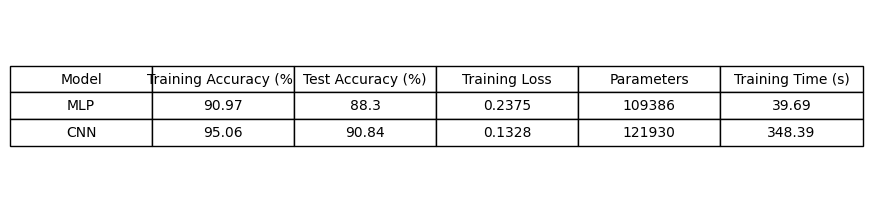

In [26]:
import pandas as pd

# Create comparison table
model_comparison = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Training Accuracy (%)": [
        MLP_results["Training Accuracy"] * 100,
        CNN_results["Training Accuracy"] * 100
    ],
    "Test Accuracy (%)": [
        MLP_results["Test Accuracy"] * 100,
        CNN_results["Test Accuracy"] * 100
    ],
    "Training Loss": [
        MLP_results["Training Loss"],
        CNN_results["Training Loss"]
    ],
    "Parameters": [
        MLP_results["Parameters"],
        CNN_results["Parameters"]
    ],
    "Training Time (s)": [
        MLP_results["Training Time"],
        CNN_results["Training Time"]
    ]
})

# Round numerical results for readability
model_comparison = model_comparison.round({
    "Training Accuracy (%)": 2,
    "Test Accuracy (%)": 2,
    "Training Loss": 4,
    "Training Time (s)": 2
})

model_comparison

# Save the comparison table as an image
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.axis('off')

table = ax.table(
    cellText=model_comparison.values,
    colLabels=model_comparison.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

plt.savefig(
    'MLP_CNN_Comparison_Table.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

The CNN achieved higher training and test accuracy than the MLP. The CNN reached 90.84% test accuracy compared with 88.30% for the MLP. However, the CNN had more trainable parameters and required considerably more training time. This shows a trade-off between classification performance and computational cost in this experiment.

#### 4.2 Compare Training Accuracy

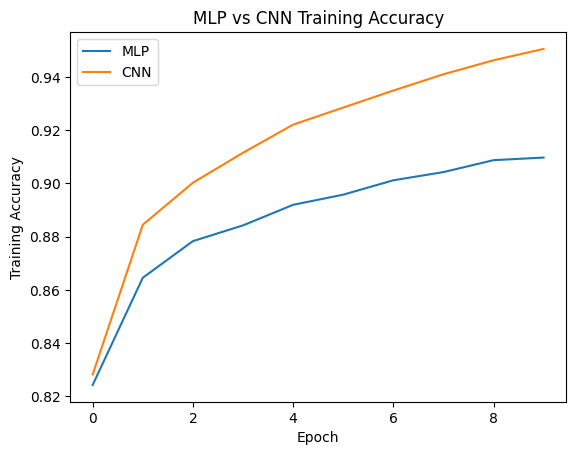

In [22]:
# Compare training accuracy of MLP and CNN
plt.plot(MLP_history.history['accuracy'], label='MLP')
plt.plot(CNN_history.history['accuracy'], label='CNN')

plt.xlabel('Epoch')
plt.ylabel('Training Accuracy')
plt.title('MLP vs CNN Training Accuracy')
plt.legend()
plt.show()

The training accuracy of both models increased over the 10 epochs. The CNN improved more consistently and reached a higher final training accuracy of 95.06%, compared with 90.97% for the MLP.

#### 4.3 Compare Training Loss

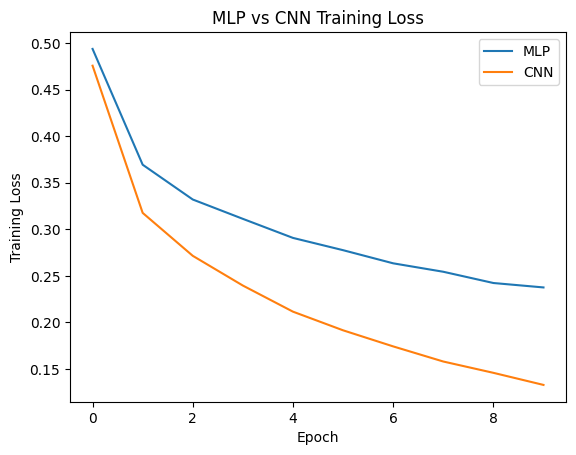

In [23]:
# Compare training loss of MLP and CNN
plt.plot(MLP_history.history['loss'], label='MLP')
plt.plot(CNN_history.history['loss'], label='CNN')

plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('MLP vs CNN Training Loss')
plt.legend()
plt.show()

The training loss decreased for both models as training progressed. The CNN reached a lower final training loss of 0.1328 compared with 0.2375 for the MLP, which is consistent with its higher training accuracy.

#### 4.4 Predict a Test Image

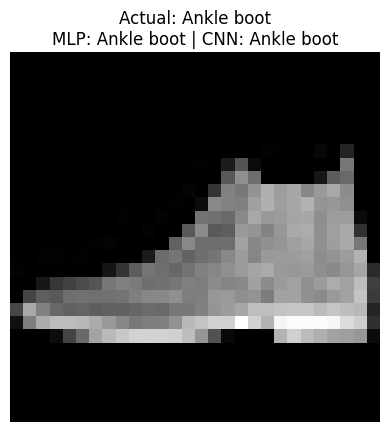

In [24]:
# Select one image from the test dataset
image_index = 0
test_image = x_test[image_index]

# Make predictions using both models
MLP_prediction = MLP_Model.predict(test_image.reshape(1, 28, 28), verbose=0)
CNN_prediction = CNN_Model.predict(test_image.reshape(1, 28, 28, 1), verbose=0)

# Get predicted class
MLP_class = MLP_prediction.argmax()
CNN_class = CNN_prediction.argmax()

# Display the image and predictions
plt.imshow(test_image, cmap='gray')
plt.title(
    f"Actual: {class_names[y_test[image_index]]}\n"
    f"MLP: {class_names[MLP_class]} | CNN: {class_names[CNN_class]}"
)
plt.axis('off')
plt.show()

Both models correctly classified the selected test image as an ankle boot. This example shows that both the MLP and CNN are capable of making correct predictions on unseen Fashion-MNIST images. However, the overall test accuracy is more reliable for comparing the models than a single prediction.